# Ancient Environmental Metagenomics (AEMG01)
## Day 3 · Practical: Authentication of ancient microbial hits

<a href="https://colab.research.google.com/github/NikolayOskolkov/AncientEnvironmentalMetagenomics/blob/main/notebooks/Day3_Authentication_shortcut.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Prerequisites:** `Day1_setup_shortcut.ipynb` (`course_paths.json`), `Day1_QC_shortcut.ipynb` (trimmed reads in `03_TRIMMED/`) and `Day2_TaxonomicProfiling_shortcut.ipynb` (the *Yersinia pestis* hit in sample10 and the abundance matrix in `06_KRAKENUNIQ_ABUNDANCE_MATRIX/`).

### Learning outcomes
After this practical you will be able to:

* explain why a taxonomic hit is only a **hypothesis** that must be confirmed,
* align reads to a candidate reference genome and inspect them in **IGV**,
* compute and interpret **depth, breadth and evenness of coverage**, **mapping quality**, **edit distance**, **percent identity** and **multi-allelic sites**,
* measure **deamination** (C→T / G→A) and **fragment length** with **mapDamage**,
* score single reads for post-mortem damage with **PMDtools** and use the scores to separate ancient from modern reads,
* test for damage statistically with **pyDamage**,
* compare a likely **true-positive** with likely **false-positive** detections and summarise the evidence.

<p align="center">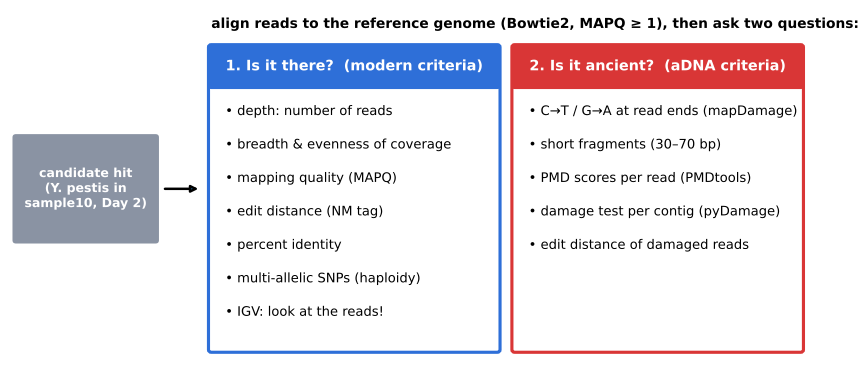<br><em>Today's question: is the organism really there, and is it really ancient?</em></p>

---
## Scientific background: "Who is there?" is only half of the question

In ancient metagenomics we try to answer two questions: **"Who is there?"** and **"How ancient?"**. Yesterday's taxonomic profiling answered the first one *provisionally*. A k-mer classifier, an aligner or an assembler can all tell us that reads resemble an organism, but none of them tells us that the detection is real or old. A detected organism may:

1. be **mis-identified** – the DNA belongs to another organism (often a relative missing from the database),
2. have a **modern origin** – a lab reagent or sequencing contaminant, or DNA of people handling the sample,
3. be of **exogenous origin** – genuinely ancient, but it entered the sample *post-mortem* (e.g. soil bacteria colonising a skeleton).

Each hit therefore has to be **followed up**. The checks fall into two groups:

* **modern validation criteria** – is the organism *present*? (evenness and breadth of coverage, alignment quality, affinity to the reference),
* **ancient-specific criteria** – is the DNA *old*? (deamination profile, fragmentation, PMD scores).

No single metric is decisive. Authentication means collecting several independent lines of evidence – which is exactly what the aMeta workflow automates (Day 5). Today we compute every metric by hand for the *Yersinia pestis* hit in **sample10**.

---
## 1. Session setup

### 1.1 Install conda
`condacolab.install()` restarts the kernel – the *"session crashed"* message is expected; continue with the next cell.

In [ ]:
!pip install -q condacolab
import condacolab
condacolab.install()

In [ ]:
import shutil, sys
mamba = shutil.which("mamba")
print("Python :", sys.executable)
print("mamba  :", mamba or "NOT FOUND")
assert mamba, "conda/mamba is not installed – run the condacolab.install() cell above and wait for the restart"
!mamba --version

### 1.2 Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

### 1.3 Install today's software

Today's tools have conflicting requirements: **mapDamage** needs specific R and Python packages, **PMDtools** is written in **Python 2.7**, and **pyDamage** has its own scientific Python stack. Installing them together into one environment would fail or break Colab's Python. We therefore install the basic tools into the main (*base*) conda environment and give each of the three tools **its own conda environment**:

| Environment | Tools | Why separate |
|---|---|---|
| base | Bowtie2, samtools, seqtk, pandas | basic tools used in `%%bash` cells (pandas for helper scripts run with conda's Python) |
| `mapdamage` | [mapDamage2](https://ginolhac.github.io/mapDamage/) + its R packages | R/Python dependencies |
| `py27` | Python 2.7 for [PMDtools](https://github.com/pontussk/PMDtools) | PMDtools does not run on Python 3 |
| `pydamage` | [pyDamage](https://github.com/maxibor/pydamage) | its own scientific Python stack |

`mamba create -y -q -n <name> -c conda-forge -c bioconda <packages>` creates a new, isolated environment called `<name>` (`-n`). In Colab, conda environments live in `/usr/local/envs/<name>`. Instead of `conda activate` (which does not work across notebook cells), we call a program from an environment by putting that environment's `bin` folder first on the `PATH` **for that one command**, e.g. `PATH=$ENVS/mapdamage/bin:$PATH mapDamage …`. This also makes sure the tool finds *its own* R and Python.

This cell takes 5–10 minutes. Logs are written to `/content/install_*.log`.

In [ ]:
!mamba install -y -q -c conda-forge -c bioconda bowtie2 samtools seqtk pandas > /content/install_base.log 2>&1
!mamba create -y -q -n mapdamage -c conda-forge -c bioconda mapdamage2 > /content/install_mapdamage.log 2>&1
!mamba create -y -q -n py27 -c conda-forge python=2.7 > /content/install_py27.log 2>&1
!mamba create -y -q -n pydamage -c conda-forge -c bioconda pydamage > /content/install_pydamage.log 2>&1
!pip install -q igv-notebook
print("done")

### 1.4 Paths, environments and helper functions

In [ ]:
import os, json, glob, subprocess

WORKDIR = "/content/drive/MyDrive/AEMG01"            # your own working folder (Day1_setup)
SHARE = json.load(open(f"{WORKDIR}/course_paths.json"))["SHARE"]
ENVS = subprocess.run(["conda", "info", "--base"], capture_output=True, text=True).stdout.strip() + "/envs"
AUTH = f"{WORKDIR}/07_AUTHENTICATION"

os.environ.update(WORKDIR=WORKDIR, SHARE=SHARE, ENVS=ENVS, AUTH=AUTH, THREADS=str(os.cpu_count()))
os.makedirs(AUTH, exist_ok=True)
os.chdir(WORKDIR)

for k in ["WORKDIR", "SHARE", "ENVS", "AUTH", "THREADS"]:
    print(f"{k:8s}: {os.environ[k]}")
print("environments:", sorted(os.listdir(ENVS)))
print("trimmed reads of sample10:",
      "✅" if os.path.exists("03_TRIMMED/sample10.trimmed.fastq.gz") else "❌ run Day1_QC_shortcut.ipynb first")
SAMPLES = open("SAMPLES.txt").read().split()

In [ ]:
%%bash
bowtie2 --version | head -1
samtools --version | head -1
echo "seqtk: $(seqtk 2>&1 | grep Version)"
PATH=$ENVS/mapdamage/bin:$PATH mapDamage --version || echo 'mapDamage not found – see /content/install_mapdamage.log'
$ENVS/py27/bin/python --version || echo 'Python 2.7 not found – see /content/install_py27.log'
MPLBACKEND=Agg PATH=$ENVS/pydamage/bin:$PATH pydamage --version || echo 'pyDamage not found – see /content/install_pydamage.log'

Helpers as on previous days. `show_file()` works for **HTML and PDF** files – mapDamage and PMDtools produce PDF plots, and the browser displays them directly inside the embedded frame.

The last line of the cell sets the environment variable `MPLBACKEND=Agg`. Colab sets it to its own notebook plotting backend, and every program started from a `%%bash` cell inherits it; Python tools in the separate conda environments (pyDamage) do not have that backend and would crash with *"… is not a valid value for backend"*. `Agg` is the standard backend that writes image files. The notebook itself has already loaded its plotting library at this point, so the inline plots in this notebook are not affected.

In [ ]:
import socket, time
from google.colab import output, files
from IPython.display import HTML, Image, display, Markdown
import pandas as pd, numpy as np, matplotlib.pyplot as plt

PORT = 8000
def _server_running(port=PORT):
    with socket.socket() as s:
        return s.connect_ex(("localhost", port)) == 0

def show_file(path, height=700):
    """Show an HTML or PDF file (path relative to WORKDIR) in an embedded frame."""
    if not _server_running():
        subprocess.Popen(["python", "-m", "http.server", str(PORT), "--directory", WORKDIR],
                         stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        time.sleep(2)
    output.serve_kernel_port_as_iframe(PORT, path="/" + path, height=height)

show_html = show_file

# The notebook's own matplotlib is already loaded (inline plots keep working).
# Programs started from %%bash cells inherit MPLBACKEND; Colab's inline backend does not
# exist in the separate conda environments (e.g. pyDamage), so give them the standard one.
os.environ["MPLBACKEND"] = "Agg"

def download(path):
    files.download(path)

print("Helpers ready")

---
## 2. Genomic hit confirmation: align the reads to the candidate genome

A k-mer classifier never aligns reads, so the first step of every follow-up is an **alignment** to the reference genome of the candidate organism. Alignments give us what k-mers cannot: *where* each read maps, *how well* (mapping quality), and *with how many mismatches* (edit distance, damage).

We download the *Y. pestis* reference genome (strain A1122) from NCBI and keep only its **chromosome** (`NC_017168.1`): the genome assembly also contains plasmids, which are small, present in many copies and partly shared with other bacteria, so they would distort coverage statistics.

| Command | Meaning |
|---|---|
| `NCBI=…; ID=…` | two shell variables, to keep the long URL readable |
| `wget $NCBI/genomes/all/GCF/000/222/975/${ID}/${ID}_genomic.fna.gz` | download the assembly (NCBI folders are built from the accession number: `000/222/975`) |
| `gunzip` | decompress |
| `echo NC_017168.1 > region.bed` | write the name of the sequence we want into a file |
| `seqtk subseq <fasta> region.bed` | extract the sequences listed in the file (here: the chromosome) |
| `bowtie2-build --large-index` | build the Bowtie2 index; `--large-index` forces the 64-bit index format (needed only for genomes > 4 Gbp, harmless here) |

Every `%%bash` cell starts with `cd "${AUTH:?…}"`: if the variable `AUTH` is empty – which happens after a runtime restart until you re-run cell 1.4 – the cell stops immediately with a clear message instead of running in the wrong folder.

The `if [ ! -f … ]` test skips the download if the file already exists, so the cell is safe to re-run.

In [ ]:
%%bash
cd "${AUTH:?AUTH is not set - run the paths cell (1.4) first}"
NCBI=https://ftp.ncbi.nlm.nih.gov; ID=GCF_000222975.1_ASM22297v1
if [ ! -f ${ID}_genomic.fna ]; then
    wget -q $NCBI/genomes/all/GCF/000/222/975/${ID}/${ID}_genomic.fna.gz
    gunzip ${ID}_genomic.fna.gz
fi
grep '>' ${ID}_genomic.fna

echo NC_017168.1 > region.bed
seqtk subseq ${ID}_genomic.fna region.bed > NC_017168.1.fasta
samtools faidx NC_017168.1.fasta
cut -f1,2 NC_017168.1.fasta.fai

bowtie2-build --large-index NC_017168.1.fasta NC_017168.1.fasta --threads $THREADS > bowtie2-build.log 2>&1
ls -lh NC_017168.1.fasta*

`samtools faidx` creates the `.fai` index (sequence name and length in the first two columns), which IGV, mapDamage and `samtools mpileup` need.

### Align, filter on mapping quality, sort and index

| Flag | Meaning |
|---|---|
| `-x NC_017168.1.fasta` | the Bowtie2 index prefix |
| `--end-to-end --very-sensitive` | whole-read alignment with the most sensitive preset (as on Day 1) |
| `-U ../03_TRIMMED/sample10.trimmed.fastq.gz` | the trimmed reads of sample10 (we deliberately use *all* trimmed reads, not only the human-free ones – a human read cannot align to a bacterial genome with MAPQ ≥ 1 anyway) |
| `samtools view -bS -h -q 1` | convert to BAM, keep the header, and keep only alignments with **MAPQ ≥ 1** |
| `samtools sort`, `samtools index` | sorted, indexed BAM – required for coverage calculations and IGV |

**Why `-q 1`?** A read that aligns equally well to several places gets **MAPQ = 0** from Bowtie2 and BWA. Such multi-mapping reads pile up in repeats (rRNA operons, insertion sequences) and fake coverage; removing them is standard practice in ancient metagenomics. We keep the unsorted BAM `Y.pestis_sample10.bam` as well, because PMDtools reads it later.

In [ ]:
%%bash
cd "${AUTH:?AUTH is not set - run the paths cell (1.4) first}"
bowtie2 --large-index -x NC_017168.1.fasta --end-to-end --threads $THREADS --very-sensitive \
        -U ../03_TRIMMED/sample10.trimmed.fastq.gz 2> bowtie2_sample10.log \
  | samtools view -bS -h -q 1 -@ $THREADS - > Y.pestis_sample10.bam
samtools sort Y.pestis_sample10.bam -@ $THREADS > Y.pestis_sample10.sorted.bam
samtools index Y.pestis_sample10.sorted.bam

echo "Bowtie2 summary:"; cat bowtie2_sample10.log
echo; echo "Reads kept with MAPQ >= 1: $(samtools view -c Y.pestis_sample10.sorted.bam)"

❓ What percentage of the reads aligned to *Y. pestis*? How many remain after the MAPQ filter? Is that number compatible with the KrakenUniq `taxReads` for *Y. pestis* in sample10 (Day 2)?

---
## 3. Modern validation criteria: is the organism really there?

### 3.1 Look at the reads in IGV

Before computing any statistic, **look** at the alignments. IGV is embedded with our own reference: `"reference": {"fastaPath": …, "indexPath": …}` loads the chromosome FASTA and its `.fai` index; `load_track` adds the sorted BAM with its `.bai` index.

> 💡 **Two practical notes on IGV in Colab.** (1) IGV reads files through the notebook, and reading them **directly from Google Drive** fails, so the helper `igv_local()` first **copies** the files it needs (BAM with its `.bai` index, FASTA with its `.fai` index) to Colab's local disk (`/content/igv`). (2) IGV takes **10–20 seconds** to appear the first time – wait before concluding that it is empty.

Things to look at:
* **Zoom out** to the whole chromosome (type `NC_017168.1` in the locus box): are the reads spread over the genome, or are there a few towers of reads?
* **Click on a read**: mapping quality, CIGAR, number of mismatches.
* **Mismatches** are coloured: are there more **red T's** near the read ends than in the middle?

In [ ]:
import os, shutil, igv_notebook

def igv_local(*paths, folder="/content/igv"):
    """Copy files (BAM + .bai, FASTA + .fai, BED, …) from Google Drive to Colab's local disk
    and return their new paths – IGV cannot read them reliably straight from Drive."""
    os.makedirs(folder, exist_ok=True)
    return [shutil.copy(p, os.path.join(folder, os.path.basename(p))) for p in paths]

igv_notebook.init()

fa, fai, bam, bai = igv_local(f"{AUTH}/NC_017168.1.fasta", f"{AUTH}/NC_017168.1.fasta.fai",
                              f"{AUTH}/Y.pestis_sample10.sorted.bam", f"{AUTH}/Y.pestis_sample10.sorted.bam.bai")
b = igv_notebook.Browser({
    "reference": {"id": "NC_017168.1", "name": "Yersinia pestis A1122 chromosome", "fastaPath": fa, "indexPath": fai},
    "locus": "NC_017168.1:1-20000"})
b.load_track({"name": "sample10 (MAPQ ≥ 1)", "path": bam, "indexPath": bai, "format": "bam", "type": "alignment"})

For comparison, this is what a **false-positive** hit looks like – thousands of reads, but stacked on a few conserved loci:

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/IGV_uneven_coverage_Y.pestis.png" width="720"><br><em>Reads from another microbe mis-aligned to the Y. pestis genome: many reads, but very uneven coverage.</em></p>

In that case, DNA reads originating from another microbe were (mis-)aligned to the *Y. pestis* reference genome. Even though many thousands of reads align, the uneven pattern argues **against** the presence of *Y. pestis*. Hence not only the number of reads (**depth**) but also the **breadth** and **evenness** of coverage matter: hits with reads spread uniformly over the genome are much more likely to be true positives.

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/depth_vs_breadth_of_coverage.png" width="620"><br><em>Depth vs breadth of coverage.</em></p>

### 3.2 Breadth of coverage with `samtools coverage`

`samtools coverage` summarises an alignment per reference sequence. Without options it prints a table: number of reads (`numreads`), bases covered by at least one read (`covbases`), **breadth** (`coverage`, % of the sequence covered), **mean depth** (`meandepth`), and mean base and mapping qualities. With `-m` it draws a text histogram of coverage along the sequence.

In [ ]:
%%bash
cd "${AUTH:?AUTH is not set - run the paths cell (1.4) first}"
samtools coverage Y.pestis_sample10.sorted.bam
echo
samtools coverage Y.pestis_sample10.sorted.bam -m

### 3.3 Evenness of coverage

Breadth alone can be misleading: 5 % of a genome may be covered either by reads spread over the whole genome or by reads concentrated in one region. **Evenness** asks *how the covered positions are distributed*.

**Step 1 – depth at every position.** `samtools depth -a` prints three columns – reference, position, number of reads – for **all** positions (`-a`), including those with zero coverage. The result (`*.boc`) has one line per base, i.e. 4.5 million lines for the *Y. pestis* chromosome.

In [ ]:
%%bash
cd "${AUTH:?AUTH is not set - run the paths cell (1.4) first}"
samtools depth -a Y.pestis_sample10.sorted.bam > Y.pestis_sample10.sorted.boc
wc -l Y.pestis_sample10.sorted.boc
head -n 3 Y.pestis_sample10.sorted.boc

**Step 2 – local breadth in tiles.** We split the genome into `N_tiles = 500` windows (~9 kb each) and compute the breadth of coverage *within each tile*. If the organism is present, every tile should be covered to a similar extent; a false positive gives a few high tiles and many empty ones.

This is the Python translation of the R code in the original course material (shown below for reference). `pd.cut(..., N_tiles, labels=False)` assigns each position to one of 500 equal-width tiles; `groupby("tile")` then computes, per tile, the fraction of positions with at least one read.

<details><summary><b>Original R code (click to expand)</b></summary>

```r
df <- read.delim("Y.pestis_sample10.sorted.boc", header = FALSE, sep = "\t")
names(df) <- c("Ref", "Pos", "N_reads")
N_tiles <- 500
step <- (max(df$Pos) - min(df$Pos)) / N_tiles
tiles <- c(0:N_tiles) * step; boc <- vector()
for(i in 1:length(tiles)) {
  df_loc <- df[df$Pos >= tiles[i] & df$Pos < tiles[i+1], ]
  boc <- append(boc, rep(sum(df_loc$N_reads > 0) / length(df_loc$N_reads), dim(df_loc)[1]))
}
boc[is.na(boc)] <- 0; df$boc <- boc
plot(df$boc ~ df$Pos, type = "s", xlab = "Genome position", ylab = "Coverage")
abline(h = 0, col = "red", lty = 2)
mtext(paste0(round((sum(df$N_reads > 0) / length(df$N_reads)) * 100, 2), "% of genome covered"), cex = 0.8)
```
</details>

In [ ]:
def tile_breadth(depth, n_tiles=500):
    """Fraction of positions with >= 1 read in each of n_tiles equal windows."""
    tiles = pd.cut(np.arange(len(depth)), n_tiles, labels=False)
    return pd.Series(depth > 0).groupby(tiles).mean()

df = pd.read_csv(f"{AUTH}/Y.pestis_sample10.sorted.boc", sep="\t", header=None,
                 names=["Ref", "Pos", "N_reads"])
depth = df["N_reads"].values
boc = tile_breadth(depth)

breadth = (depth > 0).mean()
mean_depth = depth.mean()
expected = 1 - np.exp(-mean_depth)          # Poisson expectation for randomly placed reads

plt.figure(figsize=(12, 3.5))
plt.step(np.linspace(0, len(depth), len(boc)), boc.values, where="post", color="#2E6FD8")
plt.axhline(0, color="#D93636", ls="--")
plt.xlabel("Genome position (bp)"); plt.ylabel("breadth of coverage per tile")
plt.title(f"sample10 → Y. pestis: {100*breadth:.2f}% of genome covered | mean depth {mean_depth:.3f}x")
plt.show()

print(f"observed breadth            : {100*breadth:.2f} %")
print(f"expected breadth (Poisson)  : {100*expected:.2f} %")
print(f"observed / expected         : {breadth/expected:.2f}")
print(f"tiles with no read at all   : {(boc == 0).sum()} of {len(boc)}")

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/Evenness_of_coverage.png" width="650"><br><em>Expected result: reads cover all parts of the genome uniformly – good evidence for a true positive, even though the overall breadth is low.</em></p>

**Observed vs expected breadth.** If reads land at random positions (as they should for a genome that is really present), the fraction of the genome covered at mean depth *d* is approximately **1 − e^(−d)** (Poisson distribution). A ratio **observed / expected close to 1** means the reads are spread as randomly as theory predicts. A ratio **much below 1** means the reads are clumped – the signature of mis-aligned reads from another organism.

❓ **Questions**
1. Is the coverage even along the genome? How many tiles have no reads at all?
2. Why is the total breadth low even though *Y. pestis* is (probably) truly present?
3. How close is the observed breadth to the Poisson expectation?

### 3.4 Mapping quality (MAPQ)

**MAPQ** (column 5 of a SAM/BAM record) is the aligner's confidence that the read is placed at the right position: MAPQ = −10·log10 P(wrong position). Reads that fit equally well elsewhere get low MAPQ. Here we extract column 5 with `cut -f5` from the text output of `samtools view`.

In [ ]:
%%bash
cd "${AUTH:?AUTH is not set - run the paths cell (1.4) first}"
samtools view Y.pestis_sample10.sorted.bam | cut -f5 > mapq.txt
sort -n mapq.txt | uniq -c | sort -k1,1nr | head

In [ ]:
mapq = np.loadtxt(f"{AUTH}/mapq.txt")
plt.figure(figsize=(8, 3.2))
plt.hist(mapq, bins=range(0, int(mapq.max()) + 2), color="darkred")
plt.xlabel("MAPQ"); plt.ylabel("Number of reads"); plt.title("Mapping quality, sample10 → Y. pestis")
plt.show()

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/MAPQ.png" width="600"><br><em>MAPQ histograms for two metagenomic samples.</em></p>
<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/mapq.png" width="650"><br><em>Typical MAPQ histograms for Bowtie2 and BWA alignments.</em></p>

MAPQ is computed differently by Bowtie2 and BWA, so values are not directly comparable between aligners. For both, most reads with **MAPQ ≈ 10–30 or higher** indicate a good affinity of the reads to the reference. (Bowtie2's maximum is 42.)

### 3.5 Edit distance

The **edit distance** of a read is the number of mismatches (and indel bases) between the read and the reference, stored by the aligner in the **NM tag** (`NM:i:2` = 2 differences). For a true-positive hit most reads align with **0 or 1 mismatches** and the distribution **decreases**; for a heavily damaged ancient sample the mode can be at 1–2. If the reads come from a *related* organism, the distribution is shifted to higher numbers.

We extract the read name, read length, MAPQ and NM for every read with `awk`: for each line, it loops over the optional fields (column 12 onwards), finds the one starting with `NM:i:`, and prints the number after it (`substr($i, 6)`) together with `length($10)` (column 10 is the read sequence).

In [ ]:
%%bash
cd "${AUTH:?AUTH is not set - run the paths cell (1.4) first}"
samtools view Y.pestis_sample10.sorted.bam \
  | awk -v OFS='\t' '{nm="NA"; for(i=12;i<=NF;i++) if($i ~ /^NM:i:/) nm=substr($i,6); print $1, length($10), $5, nm}' \
  > Y.pestis_sample10.read_stats.tsv
head -n 3 Y.pestis_sample10.read_stats.tsv

In [ ]:
rs = pd.read_csv(f"{AUTH}/Y.pestis_sample10.read_stats.tsv", sep="\t", header=None,
                 names=["read", "length", "mapq", "NM"])
nm_counts = rs["NM"].value_counts().sort_index()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].bar(nm_counts.index, nm_counts.values, color="#2E6FD8")
ax[0].set_xlabel("Number of mismatches (NM)"); ax[0].set_ylabel("Number of reads"); ax[0].set_title("Edit distance")

pid = np.floor(100 * (1 - rs["NM"] / rs["length"])).clip(lower=85)
pid_counts = pid.value_counts().sort_index()
ax[1].bar(pid_counts.index, pid_counts.values, color="#F08A24")
ax[1].set_xlabel("Percent identity to the reference (85 = ≤85)"); ax[1].set_title("Percent identity")
plt.tight_layout(); plt.show()
display(nm_counts.to_frame("reads").T)

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/edit_distance.png" width="520"><br><em>Expected edit-distance barplot: decreasing, with most reads having 0 or 1 mismatches.</em></p>

<details><summary><b>The same with Rsamtools in R (original course code)</b></summary>

```r
library("Rsamtools")
param <- ScanBamParam(tag = "NM")
bam <- scanBam("Y.pestis_sample10.sorted.bam", param = param)
barplot(table(bam[[1]]$tag$NM), ylab="Number of reads", xlab="Number of mismatches")
```
</details>

### 3.6 Affinity to the reference: percent identity and multi-allelic sites

**Percent identity** (right panel above) is closely related to edit distance: the fraction of read bases identical to the reference. Reads from the right species are mostly **98–100 %** identical; reads mis-aligned from a related species typically peak around **93–96 %**.

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/multialleleicSNPs.png" width="780"><br><em>Panels c–e: percent-identity distributions for correct, wrong and mixed assignments. Panels f–i: allele-frequency distributions at variable sites.</em></p>

**Haploidy / multi-allelic SNPs.** Bacteria are **haploid**: each genome position has one allele. If the aligned reads come from one strain, a position covered by several reads should show **one** base. Many positions with two or more alleles mean that reads from **more than one** species or strain have been mixed:

* panel f – few multi-allelic sites: correct assignment,
* panel g – symmetric allele frequencies: two strains/species at similar abundance,
* panel h – asymmetric: two strains at different abundance,
* panel i – many low-frequency alleles: many mis-assigned reads from relatives.

Let's count alleles ourselves. `samtools mpileup` lists, for each covered position, all read bases aligned there (`-f` reference FASTA, `-q 1` MAPQ ≥ 1, `-Q 20` base quality ≥ 20, `-B` disable base-alignment-quality recalibration). In the pileup, `.` and `,` mean "same as reference" (forward / reverse strand), letters are mismatches, and `^X`, `$`, `+3ACG`/`-2TT` mark read starts, read ends and indels.

In [ ]:
%%bash
cd "${AUTH:?AUTH is not set - run the paths cell (1.4) first}"
samtools mpileup -f NC_017168.1.fasta -q 1 -Q 20 -B Y.pestis_sample10.sorted.bam 2>/dev/null > Y.pestis_sample10.pileup
wc -l Y.pestis_sample10.pileup
awk '$4 >= 3' Y.pestis_sample10.pileup | head -n 5

The parser below removes read-start/end marks and indels from the pileup string, counts the alleles at every site with **depth ≥ 3**, and computes the frequency of the minor (second most common) allele. Because **damage** creates C→T and G→A mismatches that are *not* real alleles, we can ignore them (`IGNORE_DAMAGE = True`) – compare the results with `True` and `False`.

In [ ]:
import re
from collections import Counter

def pileup_alleles(ref, bases):
    s = re.sub(r"\^.", "", bases).replace("$", "")
    out, i = [], 0
    while i < len(s):
        c = s[i]
        if c in "+-":                                   # skip an indel: +3ACG / -2TT
            m = re.match(r"[+-](\d+)", s[i:]); i += len(m.group(0)) + int(m.group(1)); continue
        if c in ".,": out.append(ref.upper())
        elif c.upper() in "ACGT": out.append(c.upper())
        i += 1                                          # '*' (deletion) and 'N' are ignored
    return Counter(out)

def minor_allele_freqs(pileup, min_depth=3, ignore_damage=True):
    freqs, n_sites = [], 0
    with open(pileup) as f:
        for line in f:
            chrom, pos, ref, dp, bases = line.split("\t")[:5]
            if int(dp) < min_depth: continue
            cnt = pileup_alleles(ref, bases)
            if ignore_damage:
                if ref.upper() == "C": cnt.pop("T", None)
                if ref.upper() == "G": cnt.pop("A", None)
            if sum(cnt.values()) < min_depth: continue
            n_sites += 1
            top = cnt.most_common()
            if len(top) > 1:
                freqs.append(top[1][1] / sum(cnt.values()))
    return np.array(freqs), n_sites

IGNORE_DAMAGE = True
maf, n_sites = minor_allele_freqs(f"{AUTH}/Y.pestis_sample10.pileup", ignore_damage=IGNORE_DAMAGE)
print(f"sites with depth >= 3: {n_sites} | multi-allelic: {len(maf)} "
      f"({100*len(maf)/max(n_sites,1):.2f} %)")
if len(maf):
    plt.figure(figsize=(7, 3)); plt.hist(maf, bins=20, range=(0, 0.5), color="#7B4FB0")
    plt.xlabel("minor allele frequency"); plt.ylabel("sites"); plt.title("Multi-allelic sites"); plt.show()

❓ **Questions**
1. What fraction of well-covered sites is multi-allelic? Does it change when you set `IGNORE_DAMAGE = False`? Why?
2. With a mean depth well below 1×, how many sites reach depth ≥ 3? What does that mean for the power of this test in low-coverage ancient samples?

---
## 4. Ancient-specific validation criteria: is the DNA old?

Even with perfect coverage and alignment quality, the reads could come from a **modern** *Y. pestis* (e.g. laboratory contamination). DNA accumulates characteristic damage after death; showing that the reads carry it is the strongest evidence of antiquity.

### 4.1 Background: deamination and fragmentation

<p align="center">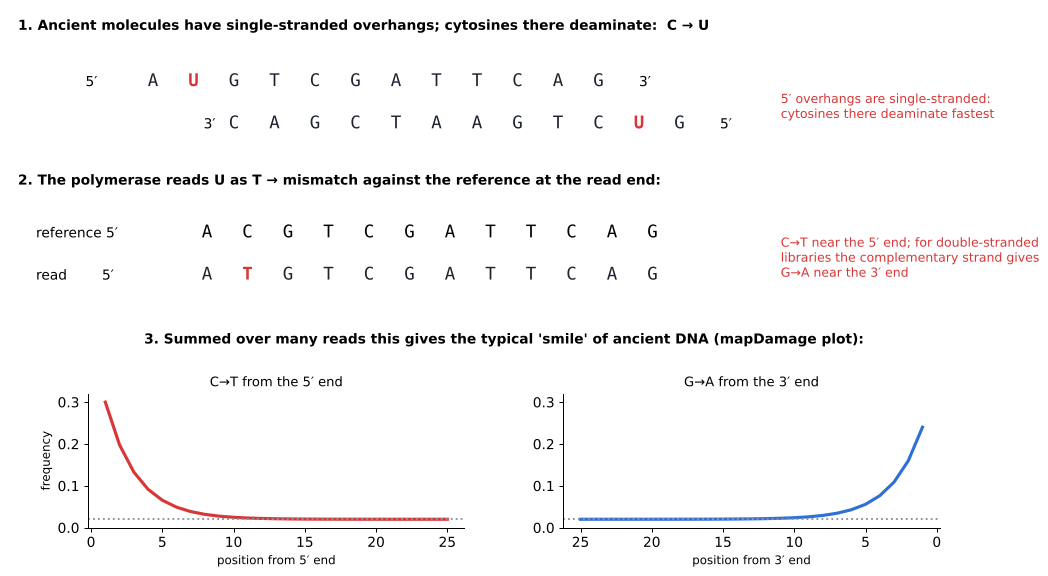<br><em>How post-mortem deamination produces C→T and G→A mismatches at read ends.</em></p>

* **Deamination.** Over time, cytosine (C) loses an amino group and becomes uracil (U). This happens much faster in **single-stranded** regions, i.e. the overhanging ends of broken molecules. During library preparation, U is copied as T, so ancient reads show an excess of **C→T** at their **5′ ends** and, for double-stranded libraries, **G→A** at their **3′ ends**. The frequency decays within ~10–15 bases from the ends. Treatment with the enzyme **UDG** (uracil-DNA glycosylase) removes most of this signal except at CpG sites.
* **Fragmentation.** Nucleases and depurination break DNA after death, so ancient molecules are short (mode **30–70 bp**). Reads longer than ~100 bp are more likely to be modern.

### 4.2 Deamination profile with mapDamage

[**mapDamage**](https://academic.oup.com/bioinformatics/article/29/13/1682/184965) counts, for each position from the read ends, how often each type of mismatch occurs, and plots the result.

| Flag | Meaning |
|---|---|
| `-i` | input BAM (sorted) |
| `-r` | the reference FASTA the reads were aligned to |
| `-d MAPDAMAGE` | output folder |
| `--merge-reference-sequences` | treat all sequences of the reference as one (useful for multi-contig references) |
| `--no-stats` | skip the slow Bayesian estimation of damage parameters; we only need the counts and plots |

`PATH=$ENVS/mapdamage/bin:$PATH` runs mapDamage from its own environment, where it also finds the R packages it uses for plotting.

In [ ]:
%%bash
cd "${AUTH:?AUTH is not set - run the paths cell (1.4) first}"
PATH=$ENVS/mapdamage/bin:$PATH mapDamage -i Y.pestis_sample10.sorted.bam -r NC_017168.1.fasta \
    -d MAPDAMAGE --merge-reference-sequences --no-stats
ls MAPDAMAGE

mapDamage writes PDF plots and the underlying tables. The main plot, `Fragmisincorporation_plot.pdf`, shows base composition around the read ends (top) and mismatch frequencies along the reads (bottom: **red = C→T**, **blue = G→A**, grey = all other substitutions):

In [ ]:
show_file("07_AUTHENTICATION/MAPDAMAGE/Fragmisincorporation_plot.pdf", height=650)

The numbers behind the curves are in `5pCtoT_freq.txt` (C→T frequency by position from the 5′ end) and `3pGtoA_freq.txt` (G→A from the 3′ end). Let's plot them ourselves and quantify the damage at the first position:

In [ ]:
ct = pd.read_csv(f"{AUTH}/MAPDAMAGE/5pCtoT_freq.txt", sep="\t")
ga = pd.read_csv(f"{AUTH}/MAPDAMAGE/3pGtoA_freq.txt", sep="\t")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
ax[0].plot(ct.iloc[:, 0], ct.iloc[:, 1], "-o", color="#D93636", ms=4); ax[0].set_title("C→T from the 5′ end")
ax[0].set_xlabel("position from 5′ end"); ax[0].set_ylabel("frequency")
ax[1].plot(ga.iloc[:, 0], ga.iloc[:, 1], "-o", color="#2E6FD8", ms=4); ax[1].set_title("G→A from the 3′ end")
ax[1].set_xlabel("position from 3′ end"); ax[1].invert_xaxis()
plt.tight_layout(); plt.show()

ct1, ga1 = ct.iloc[0, 1], ga.iloc[0, 1]
background = ct.iloc[10:, 1].mean()
print(f"C→T at 5' position 1: {ct1:.3f} | G→A at 3' position 1: {ga1:.3f} | C→T background (pos 11+): {background:.3f}")

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/deamination.png" width="650"><br><em>Expected deamination profile for ancient reads.</em></p>

❓ **Questions**
1. How high is the C→T frequency at the first position compared with the middle of the reads?
2. Is the G→A excess at the 3′ end similar? What would it mean if only C→T were elevated? (Hint: single-stranded libraries.)

### 4.3 Read-length distribution

mapDamage also writes the length distribution of the aligned reads (`lgdistribution.txt`, per strand; lines starting with `#` are comments):

In [ ]:
lg = pd.read_csv(f"{AUTH}/MAPDAMAGE/lgdistribution.txt", sep="\t", comment="#")
lg.columns = ["strand", "length", "count"]
L = lg.groupby("length")["count"].sum()
med = np.repeat(L.index.values, L.values)
plt.figure(figsize=(8, 3.2))
plt.bar(L.index, L.values, width=1, color="#3A9A4A")
plt.xlabel("read length (bp)"); plt.ylabel("reads"); plt.title(f"Read lengths, sample10 → Y. pestis (median {np.median(med):.0f} bp)")
plt.show()

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/read_length.png" width="520"><br><em>Expected read-length distribution: mode in the 30–70 bp range.</em></p>
The mode should lie within **30–70 bp** for fragmented ancient DNA; reads longer than ~100 bp are more likely to be modern. Remember that the lower end is cut off by our `-m 30` filter (Day 1).

### 4.4 PMD scores with PMDtools

mapDamage summarises damage over **all** reads. [**PMDtools**](https://github.com/pontussk/PMDtools) (Skoglund et al. 2014) instead computes a **post-mortem damage (PMD) score for every single read**: the log-likelihood ratio of the read's mismatch pattern under a model with ancient damage versus a model of sequencing errors and true polymorphisms only. Reads with **PMD score > 3** are considered reliably damaged, i.e. ancient. This single-read resolution is unique: it lets us **separate** ancient reads from modern contaminant reads of the same organism.

PMDtools needs Python 2.7 and the **MD tag** in the BAM records (which Bowtie2 writes) to reconstruct the reference base under each mismatch.

| Command | Meaning |
|---|---|
| `git clone https://github.com/pontussk/PMDtools` | download PMDtools (a single script, `pmdtools.0.60.py`) |
| `samtools view -h <bam>` | the alignments as SAM text with header (PMDtools reads SAM from its input) |
| `\| $ENVS/py27/bin/python PMDtools/pmdtools.0.60.py` | run the script with the Python 2.7 of the `py27` environment |
| `--printDS` | print the PMD score of every read (4th column) |

In [ ]:
%%bash
cd "${AUTH:?AUTH is not set - run the paths cell (1.4) first}"
[ -d PMDtools ] || git clone -q https://github.com/pontussk/PMDtools
samtools view -h Y.pestis_sample10.bam | $ENVS/py27/bin/python PMDtools/pmdtools.0.60.py --printDS > PMDscores.txt
head -n 3 PMDscores.txt
wc -l PMDscores.txt

In [ ]:
pmd = pd.read_csv(f"{AUTH}/PMDscores.txt", sep="\t", header=None)
scores = pmd[3]
plt.figure(figsize=(8, 3.2))
plt.hist(scores.clip(-10, 20), bins=150, color="#7B4FB0")
plt.axvline(3, color="#D93636", ls="--"); plt.text(3.3, plt.ylim()[1]*0.85, "PMD > 3", color="#D93636")
plt.xlabel("PMD score"); plt.ylabel("reads"); plt.title("PMD scores, sample10 → Y. pestis"); plt.show()
print(f"reads with PMD score > 3: {(scores > 3).sum()} of {len(scores)} ({100*(scores > 3).mean():.1f} %)")

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/pmd_scores.png" width="520"><br><em>Expected PMD-score distribution: a tail of reads with scores above 3.</em></p>
Most reads – even truly ancient ones – score near 0, because a read only gets a high score if it happens to carry a C→T at a position where the reference has a C near its end. The **tail above 3** is what matters.

#### Separate the damaged reads and look at them

PMDtools can also act as a filter: `--threshold 3 --header` outputs (as SAM, with header) only reads with PMD score ≥ 3. We convert them back to BAM and compare them with all reads. If the damaged reads are really *Y. pestis*, they should also align with **few mismatches** – the second edit-distance plot that aMeta uses ("edit distance of damaged reads").

In [ ]:
%%bash
cd "${AUTH:?AUTH is not set - run the paths cell (1.4) first}"
samtools view -h Y.pestis_sample10.bam \
  | $ENVS/py27/bin/python PMDtools/pmdtools.0.60.py --threshold 3 --header \
  | samtools view -b - > Y.pestis_sample10.pmd3.bam
echo "damaged reads (PMD >= 3): $(samtools view -c Y.pestis_sample10.pmd3.bam)"
samtools view Y.pestis_sample10.pmd3.bam \
  | awk -v OFS='\t' '{nm="NA"; for(i=12;i<=NF;i++) if($i ~ /^NM:i:/) nm=substr($i,6); print $1, length($10), $5, nm}' \
  > Y.pestis_sample10.pmd3.read_stats.tsv

In [ ]:
dmg = pd.read_csv(f"{AUTH}/Y.pestis_sample10.pmd3.read_stats.tsv", sep="\t", header=None,
                  names=["read", "length", "mapq", "NM"])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for d, lab, c in [(rs, "all reads", "#8A93A3"), (dmg, "PMD ≥ 3", "#D93636")]:
    v = d["NM"].value_counts(normalize=True).sort_index()
    ax[0].plot(v.index, v.values, "-o", label=lab, color=c)
    ax[1].hist(d["length"], bins=range(25, 160, 3), density=True, alpha=0.6, label=lab, color=c)
ax[0].set_xlabel("mismatches (NM)"); ax[0].set_ylabel("fraction of reads"); ax[0].set_title("Edit distance"); ax[0].legend()
ax[1].set_xlabel("read length (bp)"); ax[1].set_title("Read length"); ax[1].legend()
plt.tight_layout(); plt.show()

❓ Why do damaged reads necessarily have at least one mismatch? Is their edit-distance distribution still decreasing after that? Are the damaged reads shorter than the rest?

#### Deamination plot with PMDtools (also for UDG-treated libraries)

PMDtools can also compute a deamination profile (`--platypus`), and with `--CpG` it restricts the analysis to **CpG** sites. This is useful for **UDG/USER-treated** libraries: UDG removes uracils, but methylated cytosines in CpG context deaminate to **thymine** directly, which UDG cannot remove – so damage remains visible there. The R script `plotPMD.v2.R` from the PMDtools repository reads the table **`PMD_temp.txt`** (with an underscore – the script looks for exactly this name, so a different name gives an empty PDF) from the current folder and writes `PMD_plot.frag.pdf`; we run it with the R installed in the `mapdamage` environment (`R CMD BATCH` runs an R script non-interactively and writes its log to `plotPMD.v2.Rout`).

In [ ]:
%%bash
cd "${AUTH:?AUTH is not set - run the paths cell (1.4) first}"
samtools view Y.pestis_sample10.bam | $ENVS/py27/bin/python PMDtools/pmdtools.0.60.py --platypus > PMD_temp.txt
rm -f PMD_plot.frag.pdf
PATH=$ENVS/mapdamage/bin:$PATH R CMD BATCH PMDtools/plotPMD.v2.R
ls -lh PMD_plot.frag.pdf

In [ ]:
pdf = "07_AUTHENTICATION/PMD_plot.frag.pdf"
if os.path.getsize(pdf) > 2000:
    show_file(pdf, height=450)
else:
    print("PMD_plot.frag.pdf is empty – look at the end of 07_AUTHENTICATION/plotPMD.v2.Rout for the R error")

The same plot in Python, from the columns of `PMD_temp.txt`: `z` is the distance from the read end; `CT5`/`GA5` are C→T/G→A frequencies counted from the 5′ end and `CT3`/`GA3` from the 3′ end; the `_CpG_` columns count only cytosines in CpG context (dashed), the damage that survives UDG treatment. All other substitution types are drawn in grey.

In [ ]:
pt = pd.read_csv(f"{AUTH}/PMD_temp.txt", sep=r"\s+")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, end in [(ax[0], "5"), (ax[1], "3")]:
    for col in pt.columns:
        if col.endswith(end) and "CpG" not in col and col[:2] not in ("CT", "GA") and len(col) == 3:
            a.plot(pt.z, pt[col], color="#BBBBBB", lw=1)
    a.plot(pt.z, pt[f"CT{end}"], color="#D93636", lw=2, label="C→T")
    a.plot(pt.z, pt[f"GA{end}"], color="#2E6FD8", lw=2, label="G→A")
    a.plot(pt.z, pt[f"CT_CpG_{end}"], color="#D93636", lw=2, ls="--", label="CpG→TpG")
    a.plot(pt.z, pt[f"GA_CpG_{end}"], color="#2E6FD8", lw=2, ls="--", label="CpG→CpA")
    a.set_xlabel(f"distance from {end}′ end of read")
ax[0].set_ylabel("mismatch frequency"); ax[1].invert_xaxis(); ax[0].legend()
plt.suptitle("PMDtools deamination profile, sample10 → Y. pestis"); plt.tight_layout(); plt.show()

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/PMD_Skoglund_et_al_2015_Current_Biology.png" width="650"><br><em>PMDtools deamination plots (Skoglund et al. 2015, Current Biology).</em></p>

### 4.5 A statistical test for damage: pyDamage

mapDamage and PMDtools give plots and per-read scores, but no yes/no answer per reference. [**pyDamage**](https://doi.org/10.7717/peerj.11845) (Borry et al. 2021) fits two models to the C→T frequencies along the reads – a **null model** (flat: no damage) and a **damage model** (decaying from the 5′ end) – and tests with a likelihood-ratio test whether the damage model explains the data better. It was designed for **de-novo assembled contigs**, where running mapDamage on hundreds of thousands of contigs is impractical (Day 5); here we try it on our single reference.

* `pydamage analyze` – the analysis sub-command,
* `-w 30` – use the first 30 positions from the 5′ end for the model fit (window),
* `-p $THREADS` – number of processes,
* input: a **sorted and indexed** BAM. Results go to `pydamage_results/pydamage_results.csv`.
* `MPLBACKEND=Agg` – Colab tells every program to draw plots with its own notebook backend (environment variable `MPLBACKEND`), which does not exist in the `pydamage` environment; `Agg` is the standard backend that writes image files. Setting it in front of the command changes it for that command only.

Key output columns: `predicted_accuracy` (how reliable the damage call is, given the amount of data), `damage_model_pmax` (estimated C→T frequency at the read end), `pvalue`/`qvalue` (test of damage vs no damage), `nb_reads_aligned`, `coverage`.

In [ ]:
%%bash
cd "${AUTH:?AUTH is not set - run the paths cell (1.4) first}"
MPLBACKEND=Agg PATH=$ENVS/pydamage/bin:$PATH pydamage analyze -w 30 -p $THREADS Y.pestis_sample10.sorted.bam
ls pydamage_results

In [ ]:
pyd = pd.read_csv(f"{AUTH}/pydamage_results/pydamage_results.csv")
cols = [c for c in ["reference", "nb_reads_aligned", "coverage", "predicted_accuracy",
                    "damage_model_pmax", "null_model_p0", "pvalue", "qvalue"] if c in pyd.columns]
display(pyd[cols].T)

ctcols = [c for c in pyd.columns if c.startswith("CtoT-")]
if ctcols:
    plt.figure(figsize=(8, 3))
    plt.plot(range(len(ctcols)), pyd.loc[0, ctcols].values, "-o", color="#D93636", ms=4)
    plt.xlabel("position from 5′ end"); plt.ylabel("C→T frequency"); plt.title("pyDamage: observed C→T")
    plt.show()

❓ Is the damage model significantly better than the null model (q-value)? How confident is pyDamage (`predicted_accuracy`) given the number of reads?

---
## 5. True vs false positives: compare samples

On Day 2 the abundance matrix showed *Y. pestis* in **a few other samples** besides sample10. Are those real? Let's apply the *modern* criteria to every sample with a *Y. pestis* signal and put the results side by side. The cell aligns each sample to the chromosome exactly as in Section 2 and computes:

* number of reads (MAPQ ≥ 1), breadth, mean depth,
* **observed / expected breadth** (evenness; ≈ 1 for randomly spread reads),
* fraction of 500 tiles with at least one read,
* edit distance: mean NM and fraction of reads with NM = 0,
* median read length.

We pick the samples from the KrakenUniq abundance matrix (any sample with *Y. pestis* reads); if the matrix is missing, all samples are used. This takes a few minutes per sample.

In [ ]:
mat_file = "06_KRAKENUNIQ_ABUNDANCE_MATRIX/krakenuniq_abundance_matrix.txt"
try:
    mat = pd.read_csv(mat_file, sep="\t", index_col=0)
    row = mat.loc[[i for i in mat.index if "Yersinia pestis" in str(i)]].sum()
    to_check = sorted(set(row[row > 0].index) | {"sample10"}, key=lambda s: int(s.replace("sample", "")))
except Exception as e:
    print("abundance matrix not available:", e); to_check = SAMPLES
os.environ["TO_CHECK"] = " ".join(to_check)
print("samples to check:", to_check)

In [ ]:
%%bash
cd "${AUTH:?AUTH is not set - run the paths cell (1.4) first}"
for sample in $TO_CHECK; do
  [ -f Y.pestis_${sample}.sorted.bam ] && continue
  echo "$(date +%H:%M:%S)  aligning ${sample}"
  bowtie2 --large-index -x NC_017168.1.fasta --end-to-end --threads $THREADS --very-sensitive \
          -U ../03_TRIMMED/${sample}.trimmed.fastq.gz 2> bowtie2_${sample}.log \
    | samtools view -bS -h -q 1 -@ $THREADS - | samtools sort -@ $THREADS -o Y.pestis_${sample}.sorted.bam
  samtools index Y.pestis_${sample}.sorted.bam
done

In [ ]:
def bam_metrics(sample):
    bam = f"{AUTH}/Y.pestis_{sample}.sorted.bam"
    dep = subprocess.run(f"samtools depth -a {bam} | cut -f3", shell=True,
                         capture_output=True, text=True).stdout.split()
    depth = np.array(dep, dtype=np.int32)
    sam = subprocess.run(f"samtools view {bam}", shell=True, capture_output=True, text=True).stdout.splitlines()
    nm = [int(t[5:]) for l in sam for t in l.split("\t")[11:] if t.startswith("NM:i:")]
    lens = [len(l.split("\t")[9]) for l in sam]
    b, d = (depth > 0).mean(), depth.mean()
    exp = 1 - np.exp(-d)
    return {"reads": len(sam), "breadth_%": round(100 * b, 3), "mean_depth": round(d, 4),
            "obs/exp_breadth": round(b / exp, 2) if exp > 0 else np.nan,
            "tiles_covered_%": round(100 * (tile_breadth(depth) > 0).mean(), 1),
            "mean_NM": round(np.mean(nm), 2) if nm else np.nan,
            "NM0_%": round(100 * np.mean(np.array(nm) == 0), 1) if nm else np.nan,
            "median_length": np.median(lens) if lens else np.nan}, depth

summary, depths = {}, {}
for s in to_check:
    summary[s], depths[s] = bam_metrics(s)
summary = pd.DataFrame(summary).T
display(summary)

fig, axes = plt.subplots(len(to_check), 1, figsize=(12, 1.6 * len(to_check)), sharex=True, squeeze=False)
for ax, s in zip(axes[:, 0], to_check):
    t = tile_breadth(depths[s])
    ax.step(np.linspace(0, len(depths[s]), len(t)), t.values, where="post", color="#2E6FD8")
    ax.set_ylabel(s, rotation=0, ha="right")
axes[-1, 0].set_xlabel("genome position (bp)")
plt.suptitle("Evenness of coverage on the Y. pestis chromosome"); plt.tight_layout(); plt.show()

❓ **Questions**
1. Which samples look like **true positives** and which like **false positives**? Which metrics separate them best?
2. A sample may have very few reads but a perfectly even distribution. Is that a false positive, or just a low-abundance true positive? What would you need to decide?
3. Run the mapDamage cell (Section 4.2) for another sample by replacing `sample10` – does the damage pattern agree with your conclusion?

---
## 6. Putting the evidence together for sample10

The table below collects today's metrics for sample10 and compares each with a **rule of thumb**. The thresholds are illustrative – they are not universal cut-offs, and depend on sequencing depth, genome size and library preparation. The aMeta workflow (Day 5) computes the same kinds of metrics automatically and combines them into an **authentication score** from 0 to 10.

In [ ]:
nm_frac = rs["NM"].value_counts(normalize=True).sort_index()
decreasing = all(nm_frac.get(i, 0) >= nm_frac.get(i + 1, 0) for i in range(3))
lens = rs["length"]

checks = [
    ("Depth: reads with MAPQ ≥ 1", len(rs), "≥ 200", len(rs) >= 200),
    ("Evenness: observed / expected breadth", round(breadth / expected, 2), "≥ 0.8", breadth / expected >= 0.8),
    ("Edit distance decreasing (NM 0 ≥ 1 ≥ 2 ≥ 3)", decreasing, "True", decreasing),
    ("C→T at 5′ position 1 vs background", f"{ct1:.3f} vs {background:.3f}", "≥ 2× background", ct1 >= 2 * background),
    ("G→A at 3′ position 1", round(ga1, 3), "≥ 2× background", ga1 >= 2 * background),
    ("Median read length (bp)", int(np.median(lens)), "< 100", np.median(lens) < 100),
    ("Reads with PMD score > 3 (%)", round(100 * (scores > 3).mean(), 1), "clearly > 0", (scores > 3).mean() > 0.02),
]
tab = pd.DataFrame(checks, columns=["criterion", "sample10", "rule of thumb", "pass"])
display(tab.style.map(lambda v: "background-color:#D6EFD3" if v is True else
                      ("background-color:#F4D3D0" if v is False else ""), subset=["pass"]))

<p align="center"><img src="https://raw.githubusercontent.com/NikolayOskolkov/AncientEnvironmentalMetagenomics/main/images/aMeta_output.png" width="780"><br><em>The same evidence as produced automatically by aMeta for one microbe in one sample: deamination, evenness of coverage, edit distance (all / damaged reads), read length, PMD scores and depth.</em></p>
❓ Based on all the evidence, would you report ancient *Yersinia pestis* in sample10? What is the weakest point of the evidence, and what additional data would strengthen the claim?

---
## Summary

Today we learned that:

* a taxonomic hit is a **hypothesis**; it must be followed up with alignments to the candidate genome,
* **depth** alone is not enough: **breadth** and especially **evenness** of coverage (observed vs Poisson-expected breadth, tiles) distinguish real organisms from reads piling up on conserved regions,
* **MAPQ**, **edit distance**, **percent identity** and **multi-allelic sites** measure how well the reads fit *this* genome rather than a relative,
* **deamination** (C→T at 5′, G→A at 3′ ends) and **short fragments** are the hallmarks of ancient DNA; **mapDamage** summarises them over all reads,
* **PMDtools** scores single reads and can **separate** damaged (ancient) from undamaged (possibly modern) reads,
* **pyDamage** turns the damage signal into a statistical test, which scales to thousands of contigs,
* authentication is the **combination** of independent lines of evidence – automated in aMeta.

## Questions to think about
1. What is a false-positive microbial finding and how can we recognise it?
2. What is the difference between depth, breadth and evenness of coverage?
3. How can we separate ancient from modern DNA sequences?
4. Why might a truly ancient organism show *no* deamination signal?
5. Why can damage-induced mismatches make an ancient organism look like a "related species" in edit-distance plots, and how can we account for it?

## Readings
1. Der Sarkissian C., Velsko I.M., Fotakis A.K., Vågene Å.J., Hübner A., Fellows Yates J.A. (2021) Ancient Metagenomic Studies: Considerations for the Wider Scientific Community. *mSystems* 6:e01315-21.
2. Warinner C. et al. (2017) A Robust Framework for Microbial Archaeology. *Annu Rev Genomics Hum Genet* 18:321–356, [doi:10.1146/annurev-genom-091416-035526](https://doi.org/10.1146/annurev-genom-091416-035526).
3. Orlando L. et al. (2021) Ancient DNA analysis. *Nat Rev Methods Primers* 1:14, [doi:10.1038/s43586-020-00011-0](https://doi.org/10.1038/s43586-020-00011-0).

## Resources
* samtools: Li H. et al. (2009) *Bioinformatics* 25:2078–2079, [doi:10.1093/bioinformatics/btp352](https://doi.org/10.1093/bioinformatics/btp352)
* mapDamage2: Jónsson H. et al. (2013) *Bioinformatics* 29:1682–1684, [doi:10.1093/bioinformatics/btt193](https://doi.org/10.1093/bioinformatics/btt193)
* PMDtools: Skoglund P. et al. (2014) *PNAS* 111:2229–2234, [doi:10.1073/pnas.1318934111](https://doi.org/10.1073/pnas.1318934111)
* pyDamage: Borry M. et al. (2021) *PeerJ* 9:e11845, [doi:10.7717/peerj.11845](https://doi.org/10.7717/peerj.11845)
* aDNA-BAMPlotter: [github.com/MeriamGuellil/aDNA-BAMPlotter](https://github.com/MeriamGuellil/aDNA-BAMPlotter)
* aMeta: Pochon Z. et al. (2023), [doi:10.1101/2022.10.03.510579](https://doi.org/10.1101/2022.10.03.510579)

---
## Save this notebook as HTML

Finally, export the notebook – with all its outputs – to a single **HTML file** that you can open in any browser, keep as a record of your work, or share. [`jupyter nbconvert`](https://nbconvert.readthedocs.io/) converts the notebook file (`.ipynb`) to other formats; `--to html` selects HTML, and `--output-dir` writes the result into your own working folder (you cannot write into the instructor's shared folder).

1. **Save the notebook first** (*File ▸ Save*, or Ctrl/Cmd + S): nbconvert converts the file as it is stored in Google Drive.
2. Run the cell below. It looks for `Day3_Authentication_shortcut.ipynb` in your Drive (if you opened the notebook from GitHub, use *File ▸ Save a copy in Drive* first, or set `NB_PATH` by hand).

Interactive elements that need a running Colab session – embedded reports served by `show_html()` and IGV views – appear empty in the HTML file; tables, plots and printed output are kept.

In [ ]:
import glob, os, shutil, subprocess, sys
NB_NAME = "Day3_Authentication_shortcut.ipynb"
NB_PATH = None   # <- set by hand if the search below does not find the notebook

if NB_PATH is None:
    pats = [f"/content/drive/MyDrive/{NB_NAME}", f"/content/drive/MyDrive/*/{NB_NAME}",
            f"/content/drive/MyDrive/*/*/{NB_NAME}"]
    hits = [p for pat in pats for p in glob.glob(pat)]
    NB_PATH = max(hits, key=os.path.getmtime) if hits else None     # the most recently saved copy

OUT_DIR = os.environ.get("WORKDIR", "/content/drive/MyDrive/AEMG01")
if NB_PATH:
    print("converting", NB_PATH)
    # convert a local copy: nbconvert cannot cope with spaces in the path (e.g. "… (1)" shortcuts)
    os.makedirs("/content/nb_export", exist_ok=True)
    local_nb = shutil.copy(NB_PATH, f"/content/nb_export/{NB_NAME}")
    args = ["--to", "html", local_nb, "--output-dir", OUT_DIR]
    # use the `jupyter` command if it exists, otherwise nbconvert as a Python module
    cmd = ["jupyter", "nbconvert"] + args if shutil.which("jupyter") else [sys.executable, "-m", "nbconvert"] + args
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0 and "No module named nbconvert" in r.stderr:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nbconvert"])
        r = subprocess.run([sys.executable, "-m", "nbconvert"] + args, capture_output=True, text=True)
    print(r.stderr.strip().splitlines()[-1] if r.stderr.strip() else r.stdout)
    html = os.path.join(OUT_DIR, NB_NAME.replace(".ipynb", ".html"))
    print(("✅ HTML file: " if os.path.exists(html) else "❌ conversion failed – see the message above: ") + html)
else:
    print(f"{NB_NAME} not found in your Drive – save a copy in Drive (File ▸ Save a copy in Drive) or set NB_PATH")